# Baseline 2 — Stage 2 Full-Data Training (ResNet-50)

Full-data continuation from selected Exp15; 10 fixed epochs. This notebook preserves the recorded experiment and reviews existing evidence. Read the local record guide before running any code.


## Local record guide — Stage 2

**Objective:** Full-data continuation from selected Exp15; 10 fixed epochs.

**Architecture:** Baseline 2 uses one shared ResNet-50 backbone and separate 55-class crop and 175-class disease heads. The original method, dataset, training and analysis sections follow. The saved-evidence section at the end adds tables, existing figures and a concise discussion for this stage.

**Reading this completed record:** original execution counts, outputs and error records are preserved from `baseline2_stage2_full_data_resnet50.ipynb`. They describe the historical execution, before these presentation/path changes. New Markdown is derived from explicitly linked artifacts; it is not a newly executed experiment.

The local setup cell locates the project root before Python imports. All original code cells are guarded by `RUN_RECORDED_WORKFLOW=False` so Run All in review mode does not train, infer, or rewrite reports. Keep that setting for review; read the saved results directly. Reproducing a historical workflow requires deliberate configuration of its controls and a fresh output directory. Original overwrite protections remain.

**Navigation:** introduction → setup → dataset → model/method → training/results → visualisation → discussion. Some optional historical cells were never executed; do not treat them as results.


## 1. Configure the source checkpoint and *predecided* Stage 2 protocol

Do not change settings after training begins. Use a new `RUN_ID` for any genuinely new protocol.

In [ ]:
# Local review setup: no training, inference, or result writes.
from pathlib import Path
import os
import sys
_override = os.environ.get("B2_PROJECT_ROOT")
_start = Path(_override).expanduser().resolve() if _override else Path.cwd().resolve()
_candidates = [_start] if _override else [_start, *_start.parents]
PROJECT_DIR = next((p for p in _candidates if (p / "model.py").is_file()
                    and (p / "evaluate.py").is_file() and (p / "splits_v2").is_dir()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Open the Baseline2 workspace or set B2_PROJECT_ROOT to its root.")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
RUN_RECORDED_WORKFLOW = False  # Keep False to review this completed record.
print("Project:", PROJECT_DIR, "| Historical workflow disabled; saved outputs retained.")


In [1]:
if RUN_RECORDED_WORKFLOW:
    from pathlib import Path
    import copy, json, math, os, platform, random, time
    from contextlib import nullcontext
    import numpy as np
    import pandas as pd
    from PIL import Image
    import torch, torchvision
    from torch import nn
    from torch.utils.data import DataLoader, WeightedRandomSampler
    from torchvision import transforms as T
    from torchvision.transforms import InterpolationMode
    from model_resnet50 import MultiTaskResNet50, load_resnet50_checkpoint
    from evaluate import DPDDataset, MEAN, STD, read_metadata, validate_development_splits, sha256_file, make_candidates, require_candidate_coverage, synthetic_self_test

    PROJECT_DIR = PROJECT_DIR
    SPLIT_DIR = PROJECT_DIR / 'splits_v2'
    IMAGE_ROOT = PROJECT_DIR.parent / 'DPD_Small_dataset'
    OUTPUT_ROOT = PROJECT_DIR / 'outputs'

    # STANDARD BASELINE: Exp15 single-stage shared ResNet-50. Extension alternative is 'exp18_crt_seed123'.
    SOURCE_EXPERIMENT = 'exp15'                    # 'exp15' or 'exp18_crt_seed123'
    TRAINING_MODE = 'full'                         # 'full' or 'disease_head_only'
    ADDITIONAL_EPOCHS = 10                         # fixed before viewing Official Test
    STAGE2_BACKBONE_LR = 1e-6
    STAGE2_HEAD_LR = 1e-4
    STAGE2_SEED = 42
    RUN_STAGE2 = False                              # explicitly set True after preflight
    RUN_ID = f'stage2_{SOURCE_EXPERIMENT}_{TRAINING_MODE}_{ADDITIONAL_EPOCHS}e_seed{STAGE2_SEED}'

    SOURCE_PATHS = {
        'exp15': OUTPUT_ROOT / 'exp15_disease_weight15' / 'best_development.pt',
        'exp18_crt_seed123': OUTPUT_ROOT / 'exp18_crt_seed123' / 'best_development.pt',
    }
    CHECKPOINT_PATH = SOURCE_PATHS[SOURCE_EXPERIMENT]
    FINAL_DIR = OUTPUT_ROOT / RUN_ID
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print('Project:', PROJECT_DIR)
    print('Source:', CHECKPOINT_PATH)
    print('Output:', FINAL_DIR)
    print('Training mode:', TRAINING_MODE)
    print('Device:', DEVICE, '| PyTorch:',torch.__version__, '| torchvision:',torchvision.__version__)


Project: c:\AML\ML_Project\Baseline2
Source: c:\AML\ML_Project\Baseline2\outputs\exp15_disease_weight15\best_development.pt
Output: c:\AML\ML_Project\Baseline2\outputs\stage2_exp15_full_10e_seed42
Training mode: full
Device: cuda | PyTorch: 2.11.0+cu128 | torchvision: 0.26.0+cu128


## 2. Preflight — confirm checkpoint, 8,000 images, split hashes, candidate pairs

This cell **does not train** or inspect Official Test images.

In [2]:
if RUN_RECORDED_WORKFLOW:
    if not SPLIT_DIR.is_dir() or not IMAGE_ROOT.is_dir():
        raise FileNotFoundError('Expected splits_v2 and DPD_Small_dataset. Check PROJECT_DIR and IMAGE_ROOT.')
    if not CHECKPOINT_PATH.is_file():
        raise FileNotFoundError(f'Missing parent checkpoint: {CHECKPOINT_PATH}')
    if FINAL_DIR.exists():
        raise FileExistsError(f'Output already exists: {FINAL_DIR}. Choose a NEW RUN_ID or inspect the existing result; never overwrite.')
    if TRAINING_MODE not in ('full', 'disease_head_only'):
        raise ValueError('Invalid TRAINING_MODE')
    if SOURCE_EXPERIMENT not in SOURCE_PATHS:
        raise ValueError('Invalid SOURCE_EXPERIMENT')
    if DEVICE.type != 'cuda':
        raise RuntimeError('No CUDA GPU found. This training notebook is intended for your RTX GPU environment.')
    if ADDITIONAL_EPOCHS < 1:
        raise ValueError('ADDITIONAL_EPOCHS must be positive')
    if not (0 < STAGE2_BACKBONE_LR < 1e-5 and 0 < STAGE2_HEAD_LR < 1e-3):
        raise ValueError('Use fixed lower Stage 2 learning rates.')

    synthetic_self_test()
    parent = torch.load(CHECKPOINT_PATH, map_location='cpu', weights_only=True)
    if parent.get('stage') != 1 or parent.get('config',{}).get('backbone') != 'resnet50':
        raise ValueError('Expected a ResNet50 Stage 1 checkpoint')
    if parent['config'].get('pretrained_weights') != 'IMAGENET1K_V2':
        raise ValueError('Expected ResNet50 IMAGENET1K_V2')
    if SOURCE_EXPERIMENT == 'exp15' and abs(parent['config']['disease_loss_weight'] - 1.5)>1e-8:
        raise ValueError('Selected checkpoint is not Exp15 disease-weight 1.5')
    if SOURCE_EXPERIMENT == 'exp18_crt_seed123' and parent['config'].get('seed') != 123:
        raise ValueError('Exp18 checkpoint seed mismatch')

    frames, split_report = validate_development_splits(SPLIT_DIR)
    if split_report['sha256'] != parent['development_split']['sha256']:
        raise ValueError('Development split CSV hashes differ from parent checkpoint — STOP.')
    full_df = pd.concat([frames['train_fit'],frames['val_seen'],frames['val_unseen']], ignore_index=True)
    if len(full_df)!=8000 or full_df.filename.nunique()!=8000:
        raise ValueError('Full development training set must contain 8000 unique images')
    if full_df[['crop_id','disease_id']].drop_duplicates().empty:
        raise ValueError('No training composition pairs')
    parent_candidates = torch.as_tensor(parent['candidate_pairs'],dtype=torch.long)
    require_candidate_coverage(parent_candidates,[full_df])
    if parent['config'].get('candidate_mode') != 'all_pairs' or len(parent_candidates)!=9625:
        raise ValueError('Expected same 9625 all-pairs candidate policy as Stage 1.')
    reference_pairs = make_candidates('all_pairs')
    if not torch.equal(parent_candidates, reference_pairs):
        raise ValueError('Checkpoint candidate-pair ordering differs from canonical all-pairs ordering')
    parent_hash = sha256_file(CHECKPOINT_PATH)

    # Resolve each CSV image path; verify a small deterministic sample is decodable.
    probe_ds = DPDDataset(full_df, IMAGE_ROOT, T.Compose([T.Resize(224),T.ToTensor()]))
    for ix in np.linspace(0,len(probe_ds)-1,num=16,dtype=int):
        with Image.open(probe_ds.paths[int(ix)]) as img:
            img.convert('RGB').load()

    print('PREFLIGHT PASSED')
    print('Parent Stage 1 epoch:',parent['epoch'], '| parent source seed:',parent['config']['seed'])
    print('Full training count:',len(full_df),'| candidate pairs:',len(parent_candidates))
    print('Parent checkpoint SHA256:',parent_hash)
    print('Former val images will be TRAIN images in Stage 2. No independent Stage 2 validation will be used.')
    print('Preselected final epoch:',ADDITIONAL_EPOCHS,'| source:',SOURCE_EXPERIMENT,'| train mode:',TRAINING_MODE)


Synthetic metric + Exp06 calibration checks passed; no dataset accessed.
PREFLIGHT PASSED
Parent Stage 1 epoch: 12 | parent source seed: 42
Full training count: 8000 | candidate pairs: 9625
Parent checkpoint SHA256: 5d6115e2b62f8e4fc613c93e1e7ab459cfab43f7344ff2ad457190ccd5430cc9
Former val images will be TRAIN images in Stage 2. No independent Stage 2 validation will be used.
Preselected final epoch: 10 | source: exp15 | train mode: full


## 3. Data pipeline, sampling and optimizer

Default Exp15 Stage 2: natural shuffle, crop CE weight 1.0 and disease CE weight 1.5. Exp18 cRT + disease-head-only: keep Exp09 backbone/crop head frozen and tempered disease sampling α=0.5. These are *different* predefined training protocols, not a one-variable ablation.

In [3]:
if RUN_RECORDED_WORKFLOW:
    def seed_everything(seed):
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True


    def train_transform(config):
        return T.Compose([
            T.RandomResizedCrop(config['image_size'],scale=tuple(config['crop_scale']),interpolation=InterpolationMode.BILINEAR),
            T.RandomHorizontalFlip(p=config['flip_probability']),
            T.RandomVerticalFlip(p=config['vertical_flip_probability']),
            T.RandomRotation(config['rotation_degrees'],interpolation=InterpolationMode.NEAREST),
            T.ColorJitter(brightness=config['brightness'],contrast=config['contrast']),
            T.ToTensor(),T.Normalize(MEAN,STD),
        ])


    def make_stage2_loader(full_frame, config, train_mode):
        ds=DPDDataset(full_frame,IMAGE_ROOT,train_transform(config))
        n_workers=int(config.get('num_workers',4))
        args={'batch_size':int(config['batch_size']), 'num_workers':n_workers,
              'pin_memory':True, 'drop_last':False}
        if n_workers>0:
            args.update(prefetch_factor=2,persistent_workers=True)
        gen=torch.Generator().manual_seed(STAGE2_SEED)
        if SOURCE_EXPERIMENT=='exp18_crt_seed123':
            counts=full_frame.disease_id.value_counts()
            sample_weights=full_frame.disease_id.map(lambda label: float(counts[int(label)])**(-0.5)).to_numpy(dtype=np.float64)
            sampler=WeightedRandomSampler(torch.as_tensor(sample_weights,dtype=torch.double),num_samples=len(ds),replacement=True,generator=gen)
            args.update(sampler=sampler,shuffle=False)
        else:
            args.update(shuffle=True,generator=gen)
        return DataLoader(ds,**args)


    def make_trainable(model,mode):
        for p in model.parameters():p.requires_grad_(True)
        if mode=='disease_head_only':
            for p in model.backbone.parameters():p.requires_grad_(False)
            for p in model.crop_head.parameters():p.requires_grad_(False)
            return [{'params':list(model.disease_head.parameters()),'lr':STAGE2_HEAD_LR,'name':'disease_head'}]
        return [{'params':list(model.backbone.parameters()),'lr':STAGE2_BACKBONE_LR,'name':'backbone'},
                {'params':list(model.crop_head.parameters())+list(model.disease_head.parameters()),'lr':STAGE2_HEAD_LR,'name':'heads'}]


    def get_stage2_loss_weights():
        if TRAINING_MODE=='disease_head_only':return 0.0,1.0
        if SOURCE_EXPERIMENT=='exp15':return 1.0,1.5
        # If fully unfreezing an Exp18 cRT checkpoint, train BOTH crop + disease heads again.
        return 1.0,1.0


    def stage2_one_epoch(model,loader,optimizer,scaler,mode,amp_enabled,crop_weight,disease_weight):
        if mode=='full':model.train()
        else:
            model.backbone.eval()  # also stops BatchNorm running-stat updates
            model.crop_head.eval()
            model.disease_head.train()
        criterion=nn.CrossEntropyLoss()
        totals=np.zeros(3,dtype=np.float64)
        num=0
        for batch in loader:
            x=batch['image'].to(DEVICE,non_blocking=True)
            cy=batch['crop'].to(DEVICE,non_blocking=True)
            dy=batch['disease'].to(DEVICE,non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type='cuda',enabled=amp_enabled):
                pred=model(x)
                loss_c=criterion(pred['crop_logits'],cy) if crop_weight else torch.zeros((),device=DEVICE)
                loss_d=criterion(pred['disease_logits'],dy)
                loss=crop_weight*loss_c+disease_weight*loss_d
            if not torch.isfinite(loss):raise RuntimeError('Non-finite Stage 2 loss, stopped')
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            bs=len(x)
            totals+=bs*np.array([loss.item(),loss_c.item(),loss_d.item()])
            num+=bs
        return dict(zip(['train_total_loss','train_crop_loss','train_disease_loss'],(totals/num).tolist()))


## 4. Run full-data training — one frozen protocol, final epoch only

Preflight should pass. Change `RUN_STAGE2=True` in Section 1 and rerun the notebook. **Do not train several Stage 2 alternatives then use Official Test to pick the winner.**

In [4]:
if RUN_RECORDED_WORKFLOW:
    if RUN_STAGE2:
        # If user changed anything, the new directory check must still pass.
        if FINAL_DIR.exists():raise FileExistsError('Output exists; refusing to overwrite an earlier Stage 2 run')
        seed_everything(STAGE2_SEED)
        model,loaded_parent=load_resnet50_checkpoint(CHECKPOINT_PATH,DEVICE)
        stage2_config=copy.deepcopy(loaded_parent['config'])
        stage2_config.update({
            'stage2_source':SOURCE_EXPERIMENT, 'stage2_mode':TRAINING_MODE,
            'additional_epochs':ADDITIONAL_EPOCHS,'stage2_seed':STAGE2_SEED,
            'stage2_backbone_lr':STAGE2_BACKBONE_LR if TRAINING_MODE=='full' else None,
            'stage2_head_lr':STAGE2_HEAD_LR,
            'stage2_sample_policy':'tempered_disease_alpha_0.5' if SOURCE_EXPERIMENT=='exp18_crt_seed123' else 'natural_shuffle',
            'stage2_selection_policy':'preselected_final_epoch_no_validation',
        })
        crop_w,disease_w=get_stage2_loss_weights()
        stage2_config['stage2_crop_loss_weight']=crop_w
        stage2_config['stage2_disease_loss_weight']=disease_w
        param_groups=make_trainable(model,TRAINING_MODE)
        if TRAINING_MODE=='disease_head_only':
            assert all(not p.requires_grad for p in model.backbone.parameters())
            assert all(not p.requires_grad for p in model.crop_head.parameters())
        loader=make_stage2_loader(full_df,stage2_config,TRAINING_MODE)
        optimizer=torch.optim.AdamW(param_groups,weight_decay=stage2_config['weight_decay'])
        scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=ADDITIONAL_EPOCHS)
        amp_enabled=DEVICE.type=='cuda' and bool(stage2_config['amp'])
        scaler=torch.amp.GradScaler('cuda',enabled=amp_enabled)
        FINAL_DIR.mkdir(parents=True,exist_ok=False)
        (FINAL_DIR/'locked_protocol.json').write_text(json.dumps({
            'run_id':RUN_ID,'source_checkpoint':str(CHECKPOINT_PATH),'parent_sha256':parent_hash,
            'config':stage2_config,'train_examples':len(full_df),'split_sha256':split_report['sha256'],
            'no_official_test_used':True,'former_validation_independent':False,
        },indent=2),encoding='utf-8')
        hist=[]
        started=time.perf_counter()
        for epoch in range(1,ADDITIONAL_EPOCHS+1):
            t0=time.perf_counter()
            before=[group['lr'] for group in optimizer.param_groups]
            losses=stage2_one_epoch(model,loader,optimizer,scaler,TRAINING_MODE,amp_enabled,crop_w,disease_w)
            hist.append({'additional_epoch':epoch,'lr_groups':str(before),**losses,'seconds':time.perf_counter()-t0})
            pd.DataFrame(hist).to_csv(FINAL_DIR/'full_data_history.csv',index=False)
            scheduler.step()
            print(f'Stage 2 epoch {epoch}/{ADDITIONAL_EPOCHS} | train loss={losses["train_total_loss"]:.4f} | {time.perf_counter()-t0:.1f}s')
        final_payload={
            'stage':2,'epoch':ADDITIONAL_EPOCHS,'model_state':model.state_dict(),
            'optimizer_state':optimizer.state_dict(),'scheduler_state':scheduler.state_dict(),
            'scaler_state':scaler.state_dict(),'config':stage2_config,
            'candidate_pairs':loaded_parent['candidate_pairs'],'class_mappings':loaded_parent['class_mappings'],
            'composition_mapping':loaded_parent['composition_mapping'],
            'development_split':split_report,
            'parent_checkpoint':str(CHECKPOINT_PATH),'parent_checkpoint_sha256':parent_hash,
            'parent_best_epoch':int(loaded_parent['epoch']),
            'full_training_count':len(full_df), 'former_validation_is_independent':False,
            'training_seconds':time.perf_counter()-started,
            'environment':{'python':platform.python_version(),'torch':str(torch.__version__),
                           'torchvision':str(torchvision.__version__),'device':torch.cuda.get_device_name(0)},
        }
        tmp=FINAL_DIR/'final_full_data.tmp'
        torch.save(final_payload,tmp)
        tmp.replace(FINAL_DIR/'final_full_data.pt')
        loaded_test=torch.load(FINAL_DIR/'final_full_data.pt',map_location='cpu',weights_only=True)
        assert loaded_test['stage']==2 and loaded_test['full_training_count']==8000
        assert sha256_file(CHECKPOINT_PATH)==parent_hash
        (FINAL_DIR/'stage2_completion.json').write_text(json.dumps({
            'status':'completed','run_id':RUN_ID,'output_checkpoint':'final_full_data.pt',
            'output_sha256':sha256_file(FINAL_DIR/'final_full_data.pt'),
            'epochs':ADDITIONAL_EPOCHS,'test_metrics':None,
            'disclaimer':'Final Stage 2 checkpoint; Official Test not run here.'
        },indent=2),encoding='utf-8')
        print('STAGE 2 COMPLETE:',FINAL_DIR/'final_full_data.pt')
        print('Official Test not accessed. Choose this checkpoint BEFORE launching the separate official-evaluation notebook.')
    else:
        print('DRY PREFLIGHT ONLY — To train, change RUN_STAGE2=True in Section 1 and Run All.')


Stage 2 epoch 1/10 | train loss=1.2273 | 65.0s
Stage 2 epoch 2/10 | train loss=0.9822 | 47.1s
Stage 2 epoch 3/10 | train loss=0.8671 | 44.9s
Stage 2 epoch 4/10 | train loss=0.7677 | 46.6s
Stage 2 epoch 5/10 | train loss=0.7375 | 46.8s
Stage 2 epoch 6/10 | train loss=0.6939 | 47.0s
Stage 2 epoch 7/10 | train loss=0.6601 | 45.8s
Stage 2 epoch 8/10 | train loss=0.6474 | 45.6s
Stage 2 epoch 9/10 | train loss=0.6225 | 46.3s
Stage 2 epoch 10/10 | train loss=0.6373 | 47.0s
STAGE 2 COMPLETE: c:\AML\ML_Project\Baseline2\outputs\stage2_exp15_full_10e_seed42\final_full_data.pt
Official Test not accessed. Choose this checkpoint BEFORE launching the separate official-evaluation notebook.


## 5. Reporting and next step

- Report which **single** parent checkpoint and Stage 2 protocol you chose, any differences from your teammate’s setup, and the saved final epoch.
- `full_data_history.csv` is **training loss only**. It is **not** development or test accuracy.
- Only after the saved `final_full_data.pt` exists should you open `baseline2_official_test_resnet50.ipynb`.
- Do **not** use official test as an optimizer; if you formally pre-register multiple models for reporting, disclose them all, but do not pick the winner for further tuning based on official test.
- If official test composition labels differ from development by ID numbering, do not silently remap IDs; resolve mapping explicitly with the group first.

,additional_epoch,lr_groups,train_total_loss,train_crop_loss,train_disease_loss,seconds
0,1,"[1e-06, 0.0001]",1.2273,0.2680,0.6395,64.9371
1,2,"[9.755282581475767e-07, 9.755282581475769e-05]",0.9822,0.2163,0.5106,47.0771
2,3,"[9.045084971874736e-07, 9.045084971874737e-05]",0.8671,0.1804,0.4578,44.8841
3,4,"[7.938926261462365e-07, 7.938926261462366e-05]",0.7677,0.1632,0.4030,46.5794
4,5,"[6.545084971874736e-07, 6.545084971874737e-05]",0.7375,0.1478,0.3931,46.7639
5,6,"[5e-07, 4.9999999999999996e-05]",0.6939,0.1374,0.3710,47.0412
6,7,"[3.454915028125263e-07, 3.454915028125263e-05]",0.6601,0.1271,0.3553,45.7837
7,8,"[2.0610737385376348e-07, 2.0610737385376345e-05]",0.6474,0.1210,0.3509,45.5768
8,9,"[9.549150281252633e-08, 9.549150281252631e-06]",0.6225,0.1195,0.3353,46.3291
9,10,"[2.4471741852423233e-08, 2.447174185242323e-06]",0.6373,0.1174,0.3466,46.9744


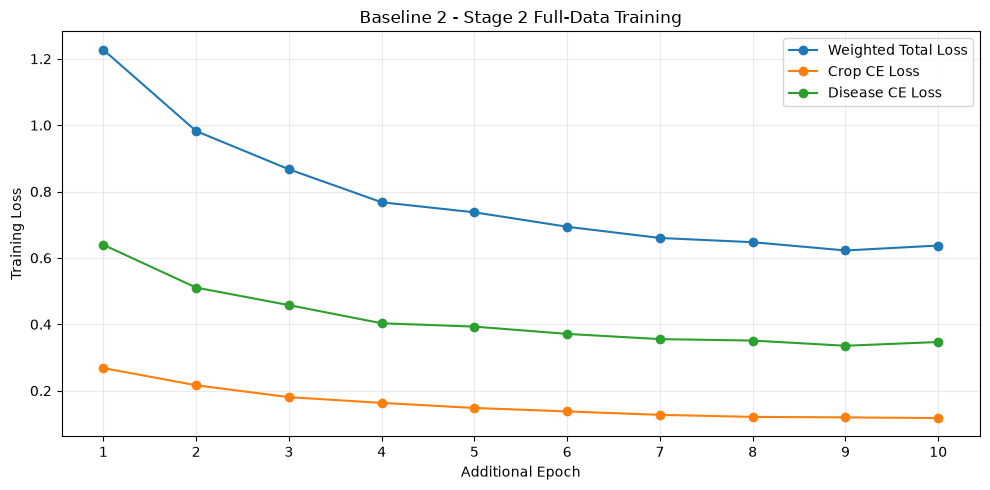

Final Total Loss: 0.6373
Graph saved to: c:\AML\ML_Project\Baseline2\outputs\stage2_exp15_full_10e_seed42\stage2_training_curves.png


In [5]:
if RUN_RECORDED_WORKFLOW:

    from pathlib import Path
    import pandas as pd
    import matplotlib.pyplot as plt
    from IPython.display import display

    result_dir = PROJECT_DIR / "outputs" / "stage2_exp15_full_10e_seed42"
    history = pd.read_csv(result_dir / "full_data_history.csv")

    # 1. Show the complete training results table
    display(history.round(4))

    # 2. Plot the three training losses
    plt.figure(figsize=(10, 5))

    for col, label in [
        ("train_total_loss", "Weighted Total Loss"),
        ("train_crop_loss", "Crop CE Loss"),
        ("train_disease_loss", "Disease CE Loss")
    ]:
        plt.plot(
            history["additional_epoch"],
            history[col],
            marker="o",
            label=label
        )

    plt.title("Baseline 2 - Stage 2 Full-Data Training")
    plt.xlabel("Additional Epoch")
    plt.ylabel("Training Loss")
    plt.xticks(history["additional_epoch"])
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        result_dir / "stage2_training_curves.png",
        dpi=180,
        bbox_inches="tight"
    )
    plt.show()

    print("Final Total Loss:", round(history["train_total_loss"].iloc[-1], 4))
    print("Graph saved to:", result_dir / "stage2_training_curves.png")


## Saved evidence and interpretation

This section was assembled from existing local artifacts on 23 November 2026. It does not rerun any model. Historical cell outputs below/above remain unchanged.

### Setup and recorded hyperparameters

| Run | Seed | Batch | LR backbone / head | WD | Crop / disease weight | Sampling |
| --- | --- | --- | --- | --- | --- | --- |
| stage2_exp15_full_10e_seed42 | 42 | 16 | 1e-05 / 0.001 | 0.001 | 1.0 / 1.5 | natural_shuffle |

Exact augmentation, scheduler, class mappings and environment versions are retained in the linked configuration files. Current source settings need not reproduce a historical execution’s environment.

### Dataset and method

Full-data training combines train-fit (6,905), seen validation (695) and unseen validation (400): 8,000 unique original training images. No independent validation is retained in this stage. Training augmentation follows the selected Exp15 recipe.

### Full-data training history

| additional_epoch | lr_groups | train_total_loss | train_crop_loss | train_disease_loss | seconds |
| --- | --- | --- | --- | --- | --- |
| 1 | [1e-06, 0.0001] | 1.2273039713129401 | 0.26804589246213434 | 0.6395053869187832 | 64.93713929998921 |
| 2 | [9.755282581475767e-07, 9.755282581475769e-05] | 0.9822469766363502 | 0.2163223575949669 | 0.510616411074996 | 47.077064799988875 |
| 3 | [9.045084971874736e-07, 9.045084971874737e-05] | 0.8670778527185321 | 0.1803990689367056 | 0.45778585600852967 | 44.88411499999347 |
| 4 | [7.938926261462365e-07, 7.938926261462366e-05] | 0.7677177686318755 | 0.16315190552175046 | 0.40304390823841096 | 46.57938379998086 |
| 5 | [6.545084971874736e-07, 6.545084971874737e-05] | 0.7374506314694882 | 0.14784275452792645 | 0.39307191647589207 | 46.763887299981434 |
| 6 | [5e-07, 4.9999999999999996e-05] | 0.6938939003497362 | 0.13741010178625584 | 0.3709892009049654 | 47.04122800001642 |
| 7 | [3.454915028125263e-07, 3.454915028125263e-05] | 0.6601020659953356 | 0.12708206123113633 | 0.3553466696590185 | 45.78369549999479 |
| 8 | [2.0610737385376348e-07, 2.0610737385376345e-05] | 0.6473728391230107 | 0.12095742569863796 | 0.3509436102360487 | 45.57678860001033 |
| 9 | [9.549150281252633e-08, 9.549150281252631e-06] | 0.6224677990153432 | 0.11947126767039298 | 0.33533102096617223 | 46.32911900000181 |
| 10 | [2.4471741852423233e-08, 2.447174185242323e-06] | 0.6372632185667754 | 0.11736409069597721 | 0.3465994161516428 | 46.974399200000335 |

No validation Top-1, Top-5, HM, or validation confusion matrix applies to this full-data training stage. Final epoch selection was fixed in advance.

### Visualisation and artifact sources


**stage2_exp15_full_10e_seed42**

[full_data_history.csv](../../../outputs/stage2_exp15_full_10e_seed42/full_data_history.csv), [locked_protocol.json](../../../outputs/stage2_exp15_full_10e_seed42/locked_protocol.json), [stage2_completion.json](../../../outputs/stage2_exp15_full_10e_seed42/stage2_completion.json)


![stage2_exp15_full_10e_seed42 — stage2_training_curves.png](../../../outputs/stage2_exp15_full_10e_seed42/stage2_training_curves.png)

### Discussion and limitations

The locked protocol continues from Exp15’s selected Stage 1 epoch-12 checkpoint on all 8,000 training images, including the former validation images. It uses exactly 10 additional epochs, backbone/head learning rates 1e-6/1e-4 and task weights 1.0/1.5. Epoch 10 was preselected; it is not a best-validation epoch. These are training loss curves only. Lower training loss cannot establish improved generalisation; there is no comparable independent pre/post evaluation.
